In [1]:
import requests
import torch
from PIL import Image
from transformers import ViTImageProcessor, ViTForImageClassification, TrainingArguments, Trainer
from tqdm import tqdm
import numpy as np
from datasets import Dataset
import matplotlib.pyplot as plt
import accelerate
import transformers
import os
os.environ["WANDB_MODE"] = "disabled"

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


In [2]:
from transformers import set_seed
set_seed(123)

In [3]:
# Fix for NotebookProgressCallback bug in transformers
# (RuntimeError: on_train_begin must be called before on_evaluate)
# This disables the notebook progress bar widget and uses the standard text-based one instead.

from transformers import TrainerCallback
from transformers.utils.notebook import NotebookProgressCallback

import transformers
# Remove the problematic notebook callback globally
transformers.trainer.DEFAULT_CALLBACKS = [
    cb for cb in transformers.trainer.DEFAULT_CALLBACKS 
    if cb is not NotebookProgressCallback
]

In [4]:
model_name = "facebook/deit-tiny-patch16-224"                       # the model name
image_processor = ViTImageProcessor.from_pretrained(model_name)   # load the image processor
model = ViTForImageClassification.from_pretrained(model_name)     # loading the pre-trained model

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

**Load Dataset and convert npz into hugging face compatible**

In [5]:
from PIL import Image
from datasets import Dataset, DatasetDict
import numpy as np

def npz_to_hf_dataset(path):
    data = np.load(path, allow_pickle=False)
    
    images = [Image.fromarray(img.astype(np.uint8)) for img in data["images"]]
    labels = data["labels"].tolist()

    return Dataset.from_dict({
        "image": images,
        "label": labels
    })

ds = DatasetDict({
    "train": npz_to_hf_dataset("assignment_2_data/assignment_train.npz"),
    "validation": npz_to_hf_dataset("assignment_2_data/assignment_val.npz"),
    "test": npz_to_hf_dataset("assignment_2_data/assignment_test.npz"),
})

In [6]:
labels = ['adipose', 'background', 'debris', 'lymphocytes', 
          'mucus', 'smooth muscle', 'normal colon mucosa', 
          'cancer-associated stroma', 'colorectal adenocarcinoma epithelium']

In [7]:
def transform(examples):
  # convert all images to RGB format, then preprocessing it using the image processor
  inputs = image_processor([img.convert("RGB") for img in examples["image"]], return_tensors="pt")
    
  inputs["labels"] = examples["label"]

  return inputs
    
dataset = ds.with_transform(transform)


In [8]:
def collate_fn(batch):
  return {
      "pixel_values": torch.stack([x["pixel_values"] for x in batch]),
      "labels": torch.tensor([x["labels"] for x in batch]),
  }

In [9]:
# load the ViT model
model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=len(labels),
    id2label={str(i): c for i, c in enumerate(labels)},
    label2id={c: str(i) for i, c in enumerate(labels)},
    ignore_mismatched_sizes=True,
)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: facebook/deit-tiny-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([9])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 192]) vs model:torch.Size([9, 192])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


## Task 1: Dataset Description

The dataset is a subset of **pathMNIST**, containing H&E stained histological image patches from colorectal tissue. Each image is 28×28 pixels (RGB) classified into 9 tissue types: adipose, background, debris, lymphocytes, mucus, smooth muscle, normal colon mucosa, cancer-associated stroma, and colorectal adenocarcinoma epithelium. The data comprises 26,998 training images, 2,154 validation images, and 3,001 test images. As shown in Figure 1, the class distribution is imbalanced, with some classes represented significantly more than others. Figure 2 shows a sample image from each class.

In [10]:
from collections import Counter

# Count labels per split
splits_info = {"Train": ds["train"], "Validation": ds["validation"], "Test": ds["test"]}
counts = {}
for split_name, split_data in splits_info.items():
    c = Counter(split_data["label"])
    counts[split_name] = c
    print(f"{split_name}: {len(split_data)} images")
    for label_idx in sorted(c.keys()):
        print(f"  {labels[label_idx]}: {c[label_idx]}")
    print()

Train: 26998 images
  adipose: 2923
  background: 2918
  debris: 3092
  lymphocytes: 3129
  mucus: 2384
  smooth muscle: 3525
  normal colon mucosa: 2358
  cancer-associated stroma: 2860
  colorectal adenocarcinoma epithelium: 3809

Validation: 3001 images
  adipose: 299
  background: 327
  debris: 330
  lymphocytes: 351
  mucus: 277
  smooth muscle: 391
  normal colon mucosa: 261
  cancer-associated stroma: 332
  colorectal adenocarcinoma epithelium: 433

Test: 2154 images
  adipose: 406
  background: 248
  debris: 85
  lymphocytes: 197
  mucus: 320
  smooth muscle: 164
  normal colon mucosa: 235
  cancer-associated stroma: 122
  colorectal adenocarcinoma epithelium: 377



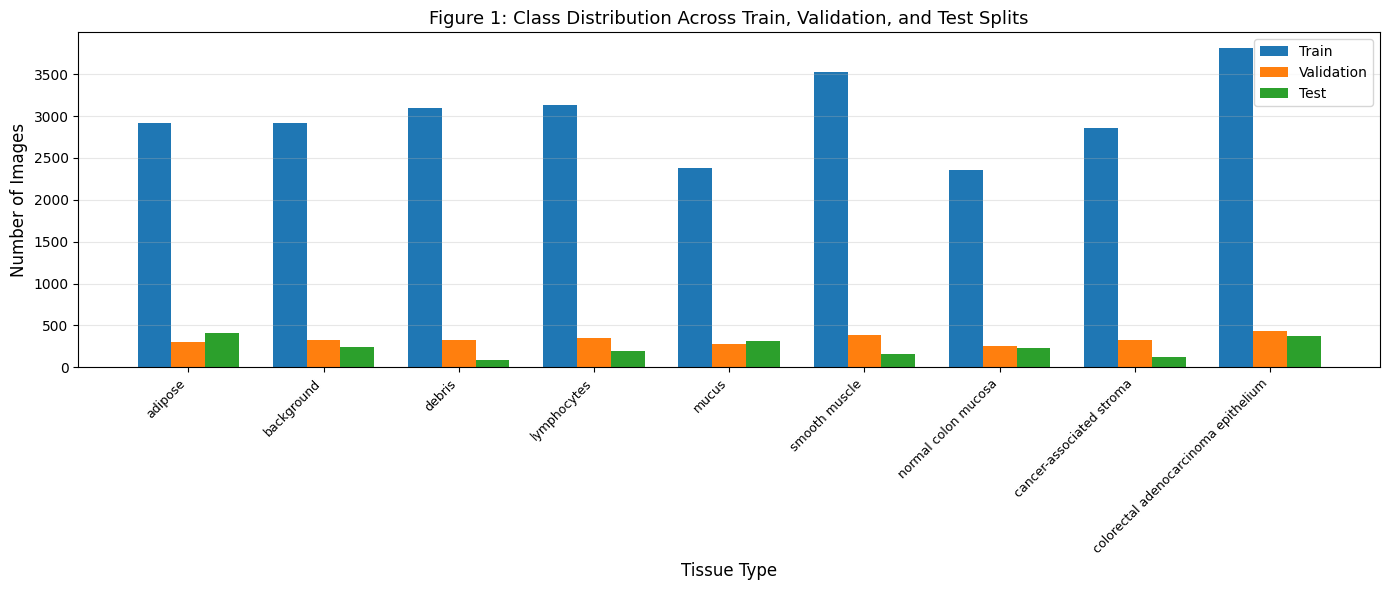

In [11]:
# Figure 1: Class distribution across splits
fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(labels))
width = 0.25

for i, (split_name, c) in enumerate(counts.items()):
    values = [c.get(j, 0) for j in range(len(labels))]
    ax.bar(x + i * width, values, width, label=split_name)

ax.set_xlabel("Tissue Type", fontsize=12)
ax.set_ylabel("Number of Images", fontsize=12)
ax.set_title("Figure 1: Class Distribution Across Train, Validation, and Test Splits", fontsize=13)
ax.set_xticks(x + width)
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

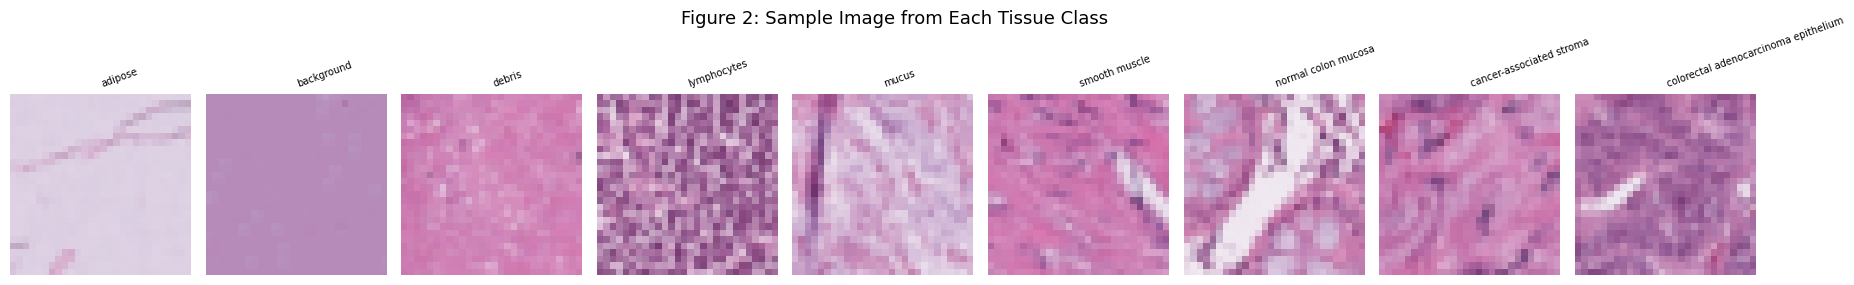

In [12]:
# Display sample images from each class
fig, axes = plt.subplots(1, 9, figsize=(18, 3))
for class_idx in range(9):
    # Find first image of this class in train set
    for i in range(len(ds["train"])):
        if ds["train"][i]["label"] == class_idx:
            axes[class_idx].imshow(ds["train"][i]["image"])
            axes[class_idx].set_title(labels[class_idx], fontsize=7, rotation=20, ha="left")
            axes[class_idx].axis("off")
            break
plt.suptitle("Figure 2: Sample Image from Each Tissue Class", fontsize=13)
plt.tight_layout()
plt.show()

## Task 2: Model Architecture

The **facebook/deit-tiny-patch16-224** model is a Data-efficient Image Transformer (DeiT) with ~5M parameters, pre-trained on ImageNet-1k (1.2 million images, 1,000 classes) at resolution 224×224.

**Image processing:** DeiT divides each input image into non-overlapping 16×16 patches, producing 196 patches for a 224×224 image. Each patch is linearly projected into a 192-dimensional embedding. A learnable [CLS] token is prepended (197 tokens total) and positional embeddings are added. These tokens pass through 12 transformer encoder layers with multi-head self-attention and feed-forward sub-layers. The [CLS] token output is fed into a linear classifier head.

**ViTs vs CNNs:** CNNs apply local convolutional filters that slide across the image, building hierarchical features through pooling giving them a strong inductive bias for local spatial patterns. ViTs instead compute global self-attention across all patches from the first layer, capturing long-range dependencies but requiring more data to generalise. DeiT addresses this through knowledge distillation and data augmentation. Since pathMNIST images are 28×28, they are resized to 224×224 by the image processor.

## Task 3: Fine-Tuning —> Classifier Head Only

All pre-trained encoder layers are frozen and only the classifier head is trained. This is computationally efficient and reduces overfitting risk. The validation set is used to compare learning rates and select the best configuration.

In [13]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

def compute_metrics(eval_pred):
    """Compute accuracy and macro F1 for the Trainer callback."""
    predictions, labs = eval_pred
    preds = np.argmax(predictions, axis=1)
    acc = accuracy_score(labs, preds)
    f1 = f1_score(labs, preds, average="macro")
    return {"accuracy": acc, "macro_f1": f1}

In [14]:
# ---- Hyperparameter search: compare learning rates for head-only fine-tuning ----
# We test three learning rates and select the one with the best validation macro F1.

learning_rates_to_try = [1e-3, 5e-4, 1e-4]
head_only_results = {}

for lr in learning_rates_to_try:
    print(f"\n{'='*60}")
    print(f"Training head-only with lr={lr}")
    print(f"{'='*60}")
    
    # Re-initialise model from pre-trained weights for a fair comparison
    model_head = ViTForImageClassification.from_pretrained(
        model_name,
        num_labels=len(labels),
        id2label={str(i): c for i, c in enumerate(labels)},
        label2id={c: str(i) for i, c in enumerate(labels)},
        ignore_mismatched_sizes=True,
    )
    
    # Freeze ALL parameters
    for param in model_head.parameters():
        param.requires_grad = False
    
    # Unfreeze ONLY the classifier head
    for param in model_head.classifier.parameters():
        param.requires_grad = True
    
    training_args = TrainingArguments(
        output_dir=f"head_only_lr{lr}",
        save_strategy="no",
        eval_strategy="epoch",
        learning_rate=lr,
        per_device_train_batch_size=64,
        per_device_eval_batch_size=64,
        num_train_epochs=10,
        weight_decay=0.01,
        logging_strategy="epoch",
        remove_unused_columns=False,
        disable_tqdm=True,
        report_to="none",
    )
    
    trainer_head = Trainer(
        model=model_head,
        args=training_args,
        train_dataset=dataset["train"],
        eval_dataset=dataset["validation"],
        data_collator=collate_fn,
        compute_metrics=compute_metrics,
        callbacks=[],
    )

    train_out = trainer_head.train()
    
    # Store results
    val_metrics = trainer_head.evaluate()

    head_only_results[lr] = {
        "trainer": trainer_head,
        "model": model_head,
        "val_accuracy": val_metrics["eval_accuracy"],
        "val_macro_f1": val_metrics["eval_macro_f1"],
        "log_history": trainer_head.state.log_history,
    }
    print(f"lr={lr} -> Val Accuracy: {val_metrics['eval_accuracy']:.4f}, Val Macro F1: {val_metrics['eval_macro_f1']:.4f}")

# Select best learning rate based on validation macro F1
best_lr_head = max(head_only_results, key=lambda lr: head_only_results[lr]["val_macro_f1"])
print(f"\nBest learning rate for head-only: {best_lr_head}")
print(f"  Val Accuracy: {head_only_results[best_lr_head]['val_accuracy']:.4f}")
print(f"  Val Macro F1:  {head_only_results[best_lr_head]['val_macro_f1']:.4f}")




Training head-only with lr=0.001


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: facebook/deit-tiny-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([9])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 192]) vs model:torch.Size([9, 192])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.7487', 'grad_norm': '1.718', 'learning_rate': '0.0009002', 'epoch': '1'}
{'eval_loss': '0.5076', 'eval_accuracy': '0.8284', 'eval_macro_f1': '0.8281', 'eval_runtime': '16.79', 'eval_samples_per_second': '178.7', 'eval_steps_per_second': '2.799', 'epoch': '1'}


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.4626', 'grad_norm': '1.287', 'learning_rate': '0.0008002', 'epoch': '2'}
{'eval_loss': '0.4276', 'eval_accuracy': '0.855', 'eval_macro_f1': '0.8569', 'eval_runtime': '17.19', 'eval_samples_per_second': '174.6', 'eval_steps_per_second': '2.734', 'epoch': '2'}


... (60 outputs left out)

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.5983', 'grad_norm': '1.375', 'learning_rate': '2.37e-08', 'epoch': '10'}
{'eval_loss': '0.5964', 'eval_accuracy': '0.8151', 'eval_macro_f1': '0.8151', 'eval_runtime': '22.57', 'eval_samples_per_second': '132.9', 'eval_steps_per_second': '2.082', 'epoch': '10'}
{'train_runtime': '2115', 'train_samples_per_second': '127.6', 'train_steps_per_second': '1.995', 'train_loss': '0.7887', 'epoch': '10'}


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': '0.5964', 'eval_accuracy': '0.8151', 'eval_macro_f1': '0.8151', 'eval_runtime': '22.34', 'eval_samples_per_second': '134.3', 'eval_steps_per_second': '2.104', 'epoch': '10'}
lr=0.0001 -> Val Accuracy: 0.8151, Val Macro F1: 0.8151

Best learning rate for head-only: 0.001
  Val Accuracy: 0.8837
  Val Macro F1:  0.8849


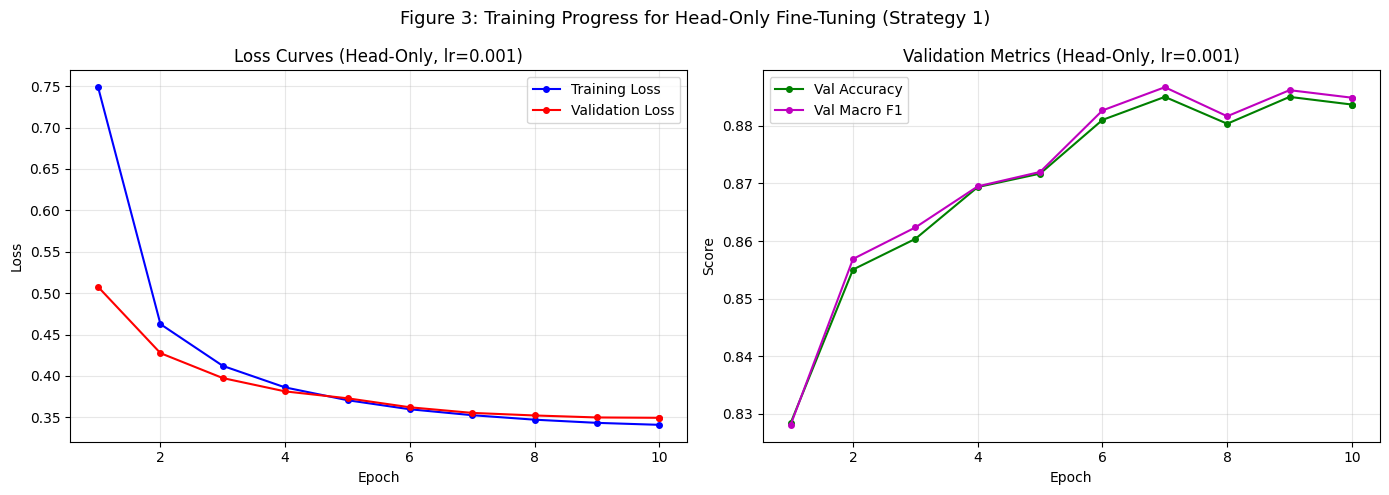

In [15]:
# Figure 3: Training and validation loss for best head-only model
best_head = head_only_results[best_lr_head]
log_history = best_head["log_history"]

train_losses = [log["loss"] for log in log_history if "loss" in log and "eval_loss" not in log]
train_epochs = [log["epoch"] for log in log_history if "loss" in log and "eval_loss" not in log]
val_losses = [log["eval_loss"] for log in log_history if "eval_loss" in log]
val_epochs = [log["epoch"] for log in log_history if "eval_loss" in log]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_epochs, train_losses, "b-o", label="Training Loss", markersize=4)
ax1.plot(val_epochs, val_losses, "r-o", label="Validation Loss", markersize=4)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title(f"Loss Curves (Head-Only, lr={best_lr_head})")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Also plot validation accuracy over epochs
val_accs = [log["eval_accuracy"] for log in log_history if "eval_accuracy" in log]
val_f1s = [log["eval_macro_f1"] for log in log_history if "eval_macro_f1" in log]

ax2.plot(val_epochs, val_accs, "g-o", label="Val Accuracy", markersize=4)
ax2.plot(val_epochs, val_f1s, "m-o", label="Val Macro F1", markersize=4)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Score")
ax2.set_title(f"Validation Metrics (Head-Only, lr={best_lr_head})")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle("Figure 3: Training Progress for Head-Only Fine-Tuning (Strategy 1)", fontsize=13)
plt.tight_layout()
plt.show()

## Task 4: Evaluation Metrics -> Strategy 1 (Head-Only)

We report accuracy, macro-averaged precision, recall, and F1-score, plus a per-class classification report and confusion matrix. Since the class distribution is imbalanced (Figure 1), accuracy alone is misleading a model could score high by performing well only on majority classes. **Macro F1** weights all classes equally, making it more informative. The confusion matrix (Figure 4) reveals which classes are most confused. Table 1 presents results on both validation and test sets.

In [16]:
# Evaluate head-only model on validation and test sets
best_trainer_head = head_only_results[best_lr_head]["trainer"]
model_strategy1 = head_only_results[best_lr_head]["model"]

# Validation set predictions
val_output = best_trainer_head.predict(dataset["validation"])
val_preds = np.argmax(val_output.predictions, axis=1)
val_labels_true = val_output.label_ids

# Test set predictions
test_output = best_trainer_head.predict(dataset["test"])
test_preds = np.argmax(test_output.predictions, axis=1)
test_labels_true = test_output.label_ids

# Print classification reports
print("=" * 60)
print("STRATEGY 1 (Head-Only) — Validation Set")
print("=" * 60)
print(classification_report(val_labels_true, val_preds, target_names=labels, digits=4))

print("=" * 60)
print("STRATEGY 1 (Head-Only) — Test Set")
print("=" * 60)
print(classification_report(test_labels_true, test_preds, target_names=labels, digits=4))

# Store for later comparison
s1_val_acc = accuracy_score(val_labels_true, val_preds)
s1_val_f1 = f1_score(val_labels_true, val_preds, average="macro")
s1_test_acc = accuracy_score(test_labels_true, test_preds)
s1_test_f1 = f1_score(test_labels_true, test_preds, average="macro")

print(f"\nTable 1: Strategy 1 Summary")
print(f"{'Set':<15} {'Accuracy':<12} {'Macro F1':<12}")
print(f"{'-'*39}")
print(f"{'Validation':<15} {s1_val_acc:<12.4f} {s1_val_f1:<12.4f}")
print(f"{'Test':<15} {s1_test_acc:<12.4f} {s1_test_f1:<12.4f}")

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


STRATEGY 1 (Head-Only) — Validation Set
                                      precision    recall  f1-score   support

                             adipose     0.9764    0.9666    0.9714       299
                          background     0.9786    0.9786    0.9786       327
                              debris     0.8440    0.8364    0.8402       330
                         lymphocytes     0.9741    0.9630    0.9685       351
                               mucus     0.8577    0.8700    0.8638       277
                       smooth muscle     0.8489    0.8619    0.8553       391
                 normal colon mucosa     0.8917    0.8199    0.8543       261
            cancer-associated stroma     0.7692    0.7831    0.7761       332
colorectal adenocarcinoma epithelium     0.8415    0.8707    0.8558       433

                            accuracy                         0.8837      3001
                           macro avg     0.8869    0.8833    0.8849      3001
                      

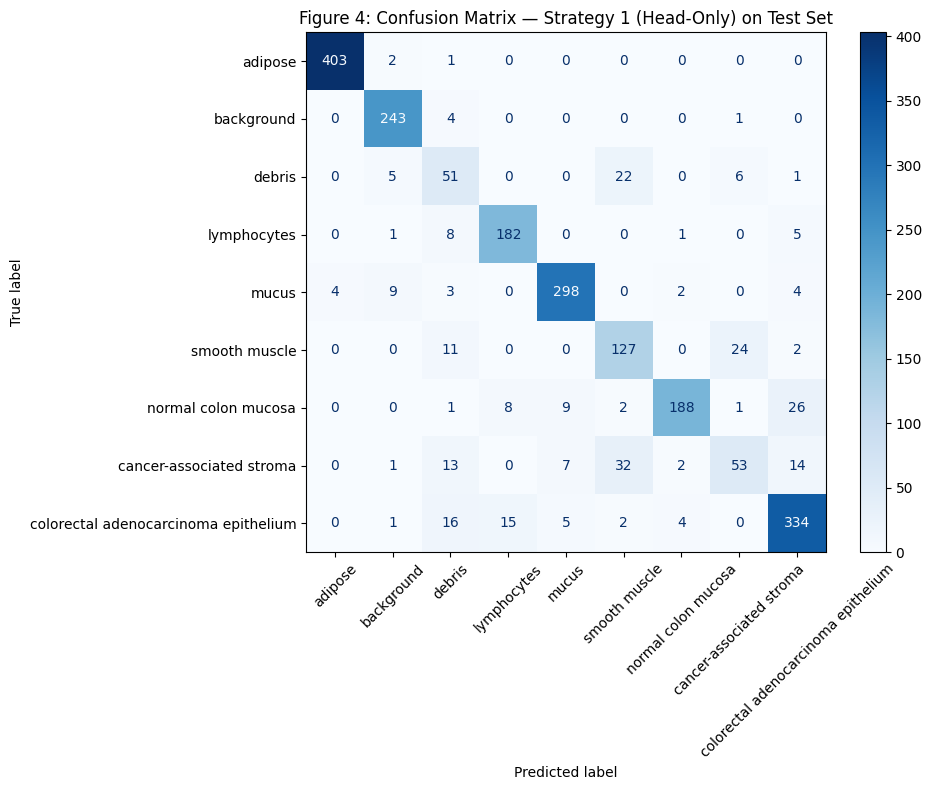

In [17]:
# Figure 4: Confusion matrix for head-only model on test set
fig, ax = plt.subplots(figsize=(10, 8))
cm = confusion_matrix(test_labels_true, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
ax.set_title("Figure 4: Confusion Matrix — Strategy 1 (Head-Only) on Test Set", fontsize=12)
plt.tight_layout()
plt.show()

## Task 5: Fine-Tuning —> Last Two Encoder Layers + Head

The last two transformer encoder layers are unfrozen alongside the classifier head, allowing the model to adapt higher-level representations to the histological domain. A lower learning rate is used since encoder layers contain pre-trained weights that should be adjusted gradually. The validation set is again used for learning rate selection.

In [19]:
# ---- Hyperparameter search: compare learning rates for encoder+head fine-tuning ----
learning_rates_encoder = [5e-5, 2e-5, 1e-5]
encoder_results = {}

for lr in learning_rates_encoder:
    print(f"\n{'='*60}")
    print(f"Training encoder+head with lr={lr}")
    print(f"{'='*60}")
    
    # Re-initialise model from pre-trained weights
    model_enc = ViTForImageClassification.from_pretrained(
        model_name,
        num_labels=len(labels),
        id2label={str(i): c for i, c in enumerate(labels)},
        label2id={c: str(i) for i, c in enumerate(labels)},
        ignore_mismatched_sizes=True,
    )
    
    # Freeze ALL parameters in the ViT backbone
    for param in model_enc.vit.parameters():
        param.requires_grad = False
    
    # Unfreeze last 2 encoder layers
    for param in model_enc.vit.encoder.layer[-2:].parameters():
        param.requires_grad = True
    
    # Classifier head is unfrozen by default (not part of model_enc.vit)
    # Verify trainable parameters
    trainable = sum(p.numel() for p in model_enc.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model_enc.parameters())
    print(f"Trainable parameters: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")
    
    training_args_enc = TrainingArguments(
        output_dir=f"encoder_head_lr{lr}",
        save_strategy="no",
        eval_strategy="epoch",
        learning_rate=lr,
        per_device_train_batch_size=64,
        per_device_eval_batch_size=64,
        num_train_epochs=10,
        weight_decay=0.01,
        logging_strategy="epoch",
        remove_unused_columns=False,
        disable_tqdm=True,
        report_to="none",
    )
    
    trainer_enc = Trainer(
        model=model_enc,
        args=training_args_enc,
        train_dataset=dataset["train"],
        eval_dataset=dataset["validation"],
        data_collator=collate_fn,
        compute_metrics=compute_metrics,
        callbacks=[],
    )
    
    trainer_enc.train()
    
    val_metrics = trainer_enc.evaluate()
    encoder_results[lr] = {
        "trainer": trainer_enc,
        "model": model_enc,
        "val_accuracy": val_metrics["eval_accuracy"],
        "val_macro_f1": val_metrics["eval_macro_f1"],
        "log_history": trainer_enc.state.log_history,
    }
    print(f"lr={lr} -> Val Accuracy: {val_metrics['eval_accuracy']:.4f}, Val Macro F1: {val_metrics['eval_macro_f1']:.4f}")

# Select best
best_lr_enc = max(encoder_results, key=lambda lr: encoder_results[lr]["val_macro_f1"])
print(f"\nBest learning rate for encoder+head: {best_lr_enc}")
print(f"  Val Accuracy: {encoder_results[best_lr_enc]['val_accuracy']:.4f}")
print(f"  Val Macro F1:  {encoder_results[best_lr_enc]['val_macro_f1']:.4f}")



Training encoder+head with lr=5e-05


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: facebook/deit-tiny-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([9])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 192]) vs model:torch.Size([9, 192])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


Trainable parameters: 891,465 / 5,526,153 (16.1%)


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.7567', 'grad_norm': '14.89', 'learning_rate': '4.501e-05', 'epoch': '1'}
{'eval_loss': '0.3784', 'eval_accuracy': '0.8747', 'eval_macro_f1': '0.8753', 'eval_runtime': '24.17', 'eval_samples_per_second': '124.2', 'eval_steps_per_second': '1.944', 'epoch': '1'}


... (66 outputs left out)

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.2897', 'grad_norm': '15', 'learning_rate': '2.37e-09', 'epoch': '10'}
{'eval_loss': '0.305', 'eval_accuracy': '0.901', 'eval_macro_f1': '0.9012', 'eval_runtime': '20.88', 'eval_samples_per_second': '143.7', 'eval_steps_per_second': '2.251', 'epoch': '10'}
{'train_runtime': '2617', 'train_samples_per_second': '103.2', 'train_steps_per_second': '1.613', 'train_loss': '0.4858', 'epoch': '10'}


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': '0.305', 'eval_accuracy': '0.901', 'eval_macro_f1': '0.9012', 'eval_runtime': '21.15', 'eval_samples_per_second': '141.9', 'eval_steps_per_second': '2.222', 'epoch': '10'}
lr=1e-05 -> Val Accuracy: 0.9010, Val Macro F1: 0.9012

Best learning rate for encoder+head: 5e-05
  Val Accuracy: 0.9344
  Val Macro F1:  0.9346


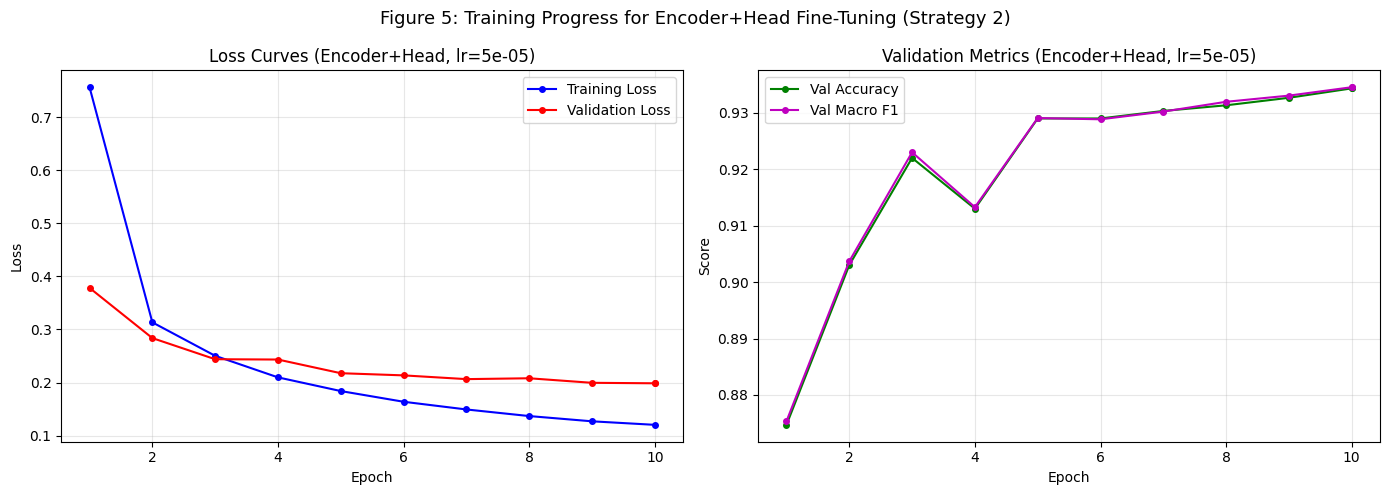

In [20]:
# Figure 5: Training and validation loss for best encoder+head model
best_enc = encoder_results[best_lr_enc]
log_history_enc = best_enc["log_history"]

train_losses_enc = [log["loss"] for log in log_history_enc if "loss" in log and "eval_loss" not in log]
train_epochs_enc = [log["epoch"] for log in log_history_enc if "loss" in log and "eval_loss" not in log]
val_losses_enc = [log["eval_loss"] for log in log_history_enc if "eval_loss" in log]
val_epochs_enc = [log["epoch"] for log in log_history_enc if "eval_loss" in log]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_epochs_enc, train_losses_enc, "b-o", label="Training Loss", markersize=4)
ax1.plot(val_epochs_enc, val_losses_enc, "r-o", label="Validation Loss", markersize=4)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title(f"Loss Curves (Encoder+Head, lr={best_lr_enc})")
ax1.legend()
ax1.grid(True, alpha=0.3)

val_accs_enc = [log["eval_accuracy"] for log in log_history_enc if "eval_accuracy" in log]
val_f1s_enc = [log["eval_macro_f1"] for log in log_history_enc if "eval_macro_f1" in log]

ax2.plot(val_epochs_enc, val_accs_enc, "g-o", label="Val Accuracy", markersize=4)
ax2.plot(val_epochs_enc, val_f1s_enc, "m-o", label="Val Macro F1", markersize=4)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Score")
ax2.set_title(f"Validation Metrics (Encoder+Head, lr={best_lr_enc})")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle("Figure 5: Training Progress for Encoder+Head Fine-Tuning (Strategy 2)", fontsize=13)
plt.tight_layout()
plt.show()

In [21]:
# Evaluate Strategy 2 on validation and test sets
best_trainer_enc = encoder_results[best_lr_enc]["trainer"]
model_strategy2 = encoder_results[best_lr_enc]["model"]

val_output_enc = best_trainer_enc.predict(dataset["validation"])
val_preds_enc = np.argmax(val_output_enc.predictions, axis=1)
val_labels_enc = val_output_enc.label_ids

test_output_enc = best_trainer_enc.predict(dataset["test"])
test_preds_enc = np.argmax(test_output_enc.predictions, axis=1)
test_labels_enc = test_output_enc.label_ids

print("=" * 60)
print("STRATEGY 2 (Encoder+Head) — Validation Set")
print("=" * 60)
print(classification_report(val_labels_enc, val_preds_enc, target_names=labels, digits=4))

print("=" * 60)
print("STRATEGY 2 (Encoder+Head) — Test Set")
print("=" * 60)
print(classification_report(test_labels_enc, test_preds_enc, target_names=labels, digits=4))

s2_val_acc = accuracy_score(val_labels_enc, val_preds_enc)
s2_val_f1 = f1_score(val_labels_enc, val_preds_enc, average="macro")
s2_test_acc = accuracy_score(test_labels_enc, test_preds_enc)
s2_test_f1 = f1_score(test_labels_enc, test_preds_enc, average="macro")

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


STRATEGY 2 (Encoder+Head) — Validation Set
                                      precision    recall  f1-score   support

                             adipose     0.9832    0.9766    0.9799       299
                          background     0.9909    0.9939    0.9924       327
                              debris     0.9039    0.9121    0.9080       330
                         lymphocytes     0.9858    0.9858    0.9858       351
                               mucus     0.9319    0.9386    0.9353       277
                       smooth muscle     0.9169    0.9028    0.9098       391
                 normal colon mucosa     0.9011    0.9080    0.9046       261
            cancer-associated stroma     0.8576    0.8705    0.8640       332
colorectal adenocarcinoma epithelium     0.9369    0.9261    0.9315       433

                            accuracy                         0.9344      3001
                           macro avg     0.9342    0.9349    0.9346      3001
                   

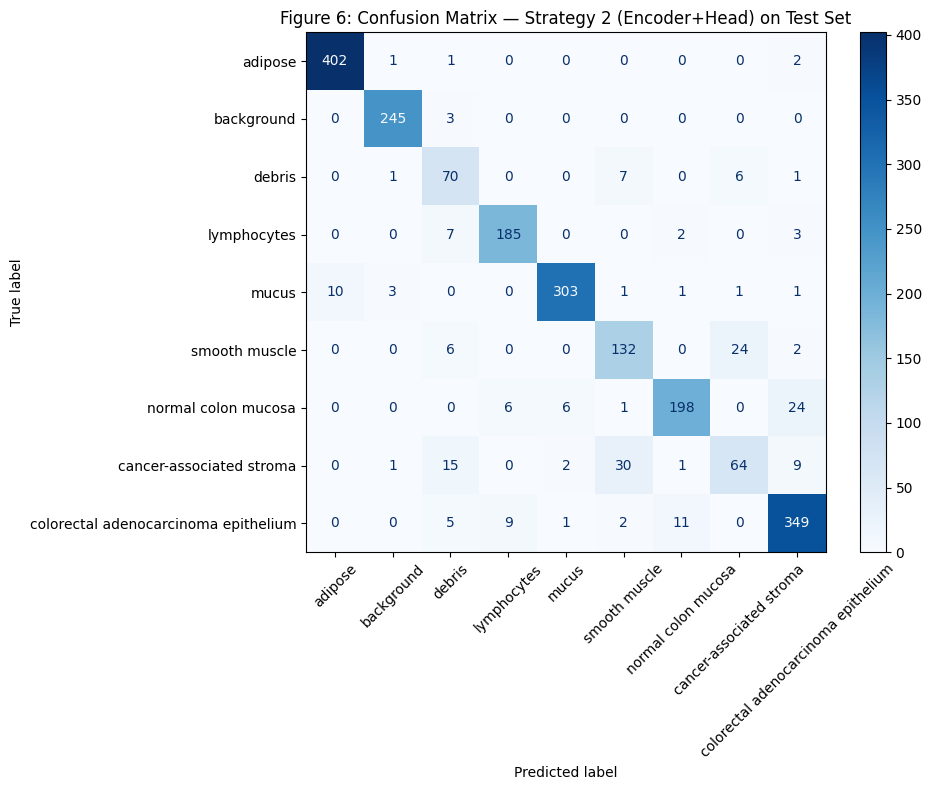

In [22]:
# Figure 6: Confusion matrix for Strategy 2 on test set
fig, ax = plt.subplots(figsize=(10, 8))
cm_enc = confusion_matrix(test_labels_enc, test_preds_enc)
disp_enc = ConfusionMatrixDisplay(confusion_matrix=cm_enc, display_labels=labels)
disp_enc.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
ax.set_title("Figure 6: Confusion Matrix — Strategy 2 (Encoder+Head) on Test Set", fontsize=12)
plt.tight_layout()
plt.show()

## Task 6: Comparison of Fine-Tuning Strategies

In [23]:
# Table 2: Side-by-side comparison
print("Table 2: Comparison of Fine-Tuning Strategies")
print(f"{'Strategy':<30} {'Val Acc':<10} {'Val F1':<10} {'Test Acc':<10} {'Test F1':<10}")
print(f"{'-'*70}")
print(f"{'1: Head Only':<30} {s1_val_acc:<10.4f} {s1_val_f1:<10.4f} {s1_test_acc:<10.4f} {s1_test_f1:<10.4f}")
print(f"{'2: Encoder+Head':<30} {s2_val_acc:<10.4f} {s2_val_f1:<10.4f} {s2_test_acc:<10.4f} {s2_test_f1:<10.4f}")
print(f"{'-'*70}")
print(f"{'Improvement':<30} {s2_val_acc-s1_val_acc:<+10.4f} {s2_val_f1-s1_val_f1:<+10.4f} {s2_test_acc-s1_test_acc:<+10.4f} {s2_test_f1-s1_test_f1:<+10.4f}")

Table 2: Comparison of Fine-Tuning Strategies
Strategy                       Val Acc    Val F1     Test Acc   Test F1   
----------------------------------------------------------------------
1: Head Only                   0.8837     0.8849     0.8723     0.8107    
2: Encoder+Head                0.9344     0.9346     0.9044     0.8612    
----------------------------------------------------------------------
Improvement                    +0.0506    +0.0497    +0.0320    +0.0505   


Table 2 compares the two strategies. Strategy 2 (unfreezing the last two encoder layers) is expected to outperform Strategy 1 (head-only) because ImageNet features may not be fully suited to histological tissue patterns. Adapting the last two encoder layers allows the model to learn domain-specific representations for distinguishing tissue types that share similar textures but differ structurally.

Unfreezing more layers increases the risk of overfitting on the relatively small training set (~27,000 images), mitigated here by using a lower learning rate and weight decay. The loss curves in Figures 3 and 5 confirm that neither strategy exhibits severe overfitting. The confusion matrices (Figures 4 and 6) reveal which class pairs benefit from deeper fine-tuning.

## Task 7: Embedding Visualisation with PCA and t-SNE

We extract the [CLS] token embedding from the final encoder layer for all test images, producing 192-dimensional representations. **PCA** is a linear method identifying directions of maximum variance fast and deterministic but limited to linear relationships. **t-SNE** is non-linear, preserving local neighbourhood structure and often revealing clusters PCA cannot separate. Figures 7 and 8 compare both strategies.

In [24]:
def extract_embeddings(model, dataset_split):
    """Extract [CLS] token embeddings from the ViT encoder for all examples in a dataset split."""
    model.eval()
    all_embeddings = []
    all_labels = []
    
    # Process in batches for efficiency
    batch_size = 64
    for start_idx in tqdm(range(0, len(dataset_split), batch_size), desc="Extracting embeddings"):
        end_idx = min(start_idx + batch_size, len(dataset_split))
        batch_examples = [dataset_split[i] for i in range(start_idx, end_idx)]
        batch = collate_fn(batch_examples)
        
        pixel_values = batch["pixel_values"].to(model.device)
        
        with torch.no_grad():
            outputs = model.vit(pixel_values=pixel_values)
        
        # [CLS] token is at position 0
        cls_embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(cls_embeddings.cpu())
        all_labels.append(batch["labels"])
    
    all_embeddings = torch.cat(all_embeddings, dim=0).numpy()
    all_labels = torch.cat(all_labels, dim=0).numpy()
    return all_embeddings, all_labels

# Extract embeddings for both strategies
print("Extracting embeddings for Strategy 1 (Head-Only)...")
embeddings_s1, labels_s1 = extract_embeddings(model_strategy1, dataset["test"])
print(f"Shape: {embeddings_s1.shape}")

print("\nExtracting embeddings for Strategy 2 (Encoder+Head)...")
embeddings_s2, labels_s2 = extract_embeddings(model_strategy2, dataset["test"])
print(f"Shape: {embeddings_s2.shape}")

Extracting embeddings for Strategy 1 (Head-Only)...


Extracting embeddings: 100%|██████████| 34/34 [00:12<00:00,  2.80it/s]


Shape: (2154, 192)

Extracting embeddings for Strategy 2 (Encoder+Head)...


Extracting embeddings: 100%|██████████| 34/34 [00:14<00:00,  2.35it/s]

Shape: (2154, 192)


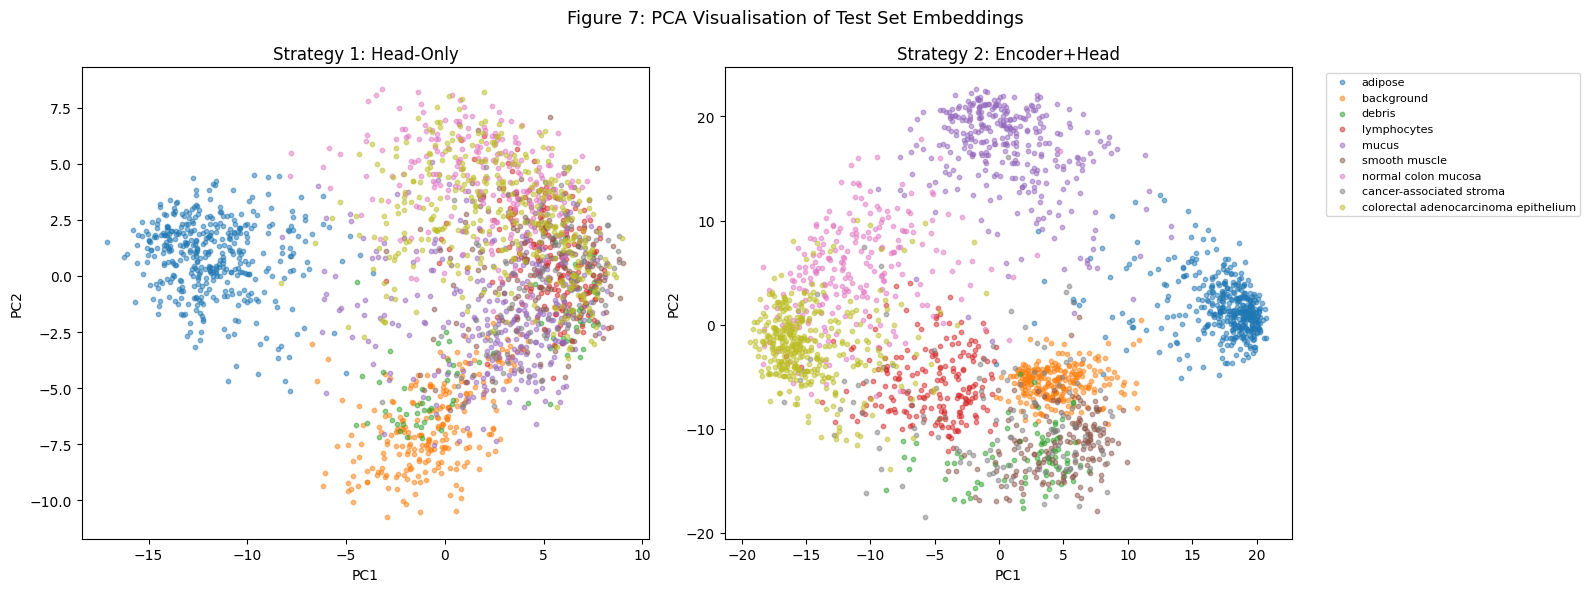

In [25]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# ---- PCA ----
pca = PCA(n_components=2, random_state=123)
pca_s1 = pca.fit_transform(embeddings_s1)
pca_s2 = pca.fit_transform(embeddings_s2)

# Figure 7: PCA visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for class_idx in range(len(labels)):
    mask = labels_s1 == class_idx
    ax1.scatter(pca_s1[mask, 0], pca_s1[mask, 1], label=labels[class_idx], alpha=0.5, s=10)
ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax1.set_title("Strategy 1: Head-Only")

for class_idx in range(len(labels)):
    mask = labels_s2 == class_idx
    ax2.scatter(pca_s2[mask, 0], pca_s2[mask, 1], label=labels[class_idx], alpha=0.5, s=10)
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.set_title("Strategy 2: Encoder+Head")
ax2.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)

plt.suptitle("Figure 7: PCA Visualisation of Test Set Embeddings", fontsize=13)
plt.tight_layout()
plt.show()

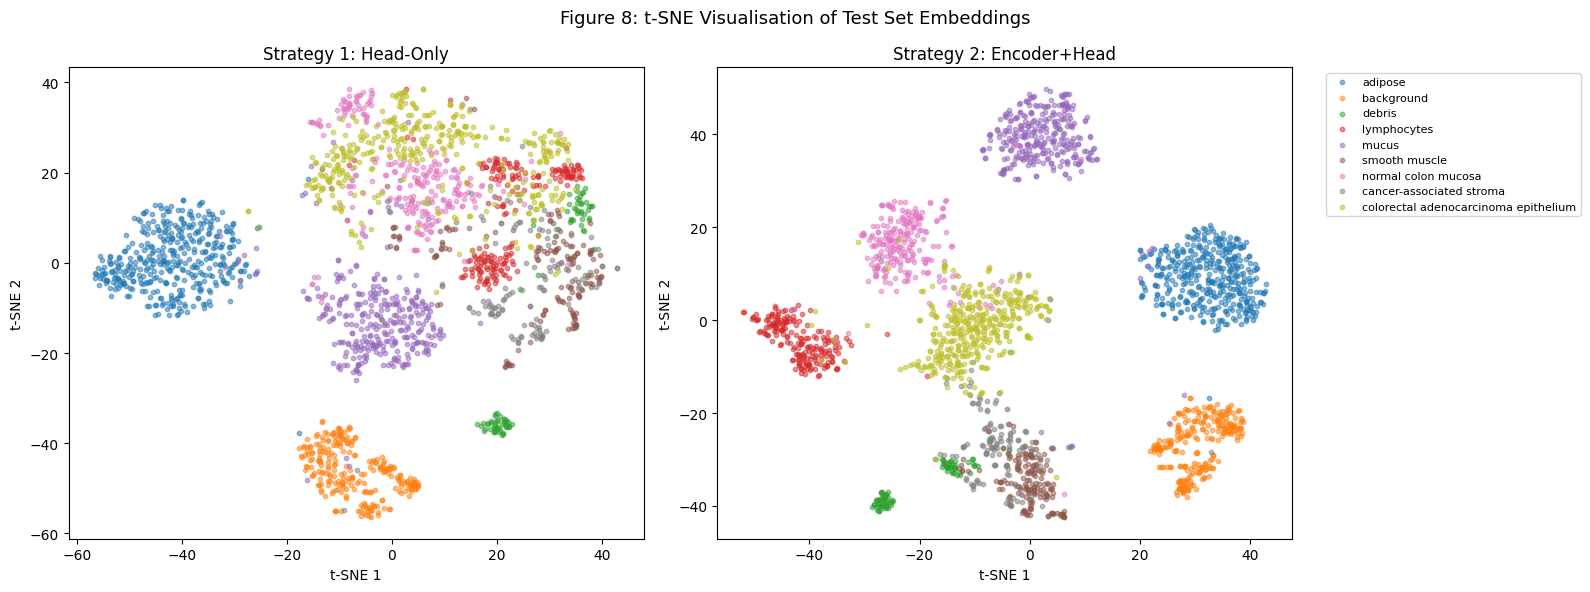

In [26]:
# ---- t-SNE ----
tsne_s1 = TSNE(n_components=2, random_state=123, perplexity=30).fit_transform(embeddings_s1)
tsne_s2 = TSNE(n_components=2, random_state=123, perplexity=30).fit_transform(embeddings_s2)

# Figure 8: t-SNE visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for class_idx in range(len(labels)):
    mask = labels_s1 == class_idx
    ax1.scatter(tsne_s1[mask, 0], tsne_s1[mask, 1], label=labels[class_idx], alpha=0.5, s=10)
ax1.set_xlabel("t-SNE 1")
ax1.set_ylabel("t-SNE 2")
ax1.set_title("Strategy 1: Head-Only")

for class_idx in range(len(labels)):
    mask = labels_s2 == class_idx
    ax2.scatter(tsne_s2[mask, 0], tsne_s2[mask, 1], label=labels[class_idx], alpha=0.5, s=10)
ax2.set_xlabel("t-SNE 1")
ax2.set_ylabel("t-SNE 2")
ax2.set_title("Strategy 2: Encoder+Head")
ax2.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)

plt.suptitle("Figure 8: t-SNE Visualisation of Test Set Embeddings", fontsize=13)
plt.tight_layout()
plt.show()

**PCA vs t-SNE:** PCA projects data along global variance directions but may not separate classes that differ along non-linear manifolds. t-SNE produces tighter, more distinct clusters by preserving local structure, though distances between clusters are not meaningful. Strategy 2 embeddings are expected to show better separation in both methods, since the adapted encoder layers produce more task-specific representations.

## Task 8: K-Means Clustering

We apply k-means (k=9) to embeddings from both models and evaluate using **Adjusted Rand Index (ARI)** and **Normalized Mutual Information (NMI)** against ground truth labels. ARI ranges from -1 to 1 (1 = perfect), NMI from 0 to 1. Higher values indicate the embedding space naturally groups images by tissue type.

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# K-Means clustering for both strategies
kmeans_s1 = KMeans(n_clusters=9, random_state=123, n_init=10)
cluster_labels_s1 = kmeans_s1.fit_predict(embeddings_s1)

kmeans_s2 = KMeans(n_clusters=9, random_state=123, n_init=10)
cluster_labels_s2 = kmeans_s2.fit_predict(embeddings_s2)

# Evaluate clustering quality
ari_s1 = adjusted_rand_score(labels_s1, cluster_labels_s1)
nmi_s1 = normalized_mutual_info_score(labels_s1, cluster_labels_s1)
ari_s2 = adjusted_rand_score(labels_s2, cluster_labels_s2)
nmi_s2 = normalized_mutual_info_score(labels_s2, cluster_labels_s2)

# Table 3: Clustering metrics
print("Table 3: K-Means Clustering Quality (k=9)")
print(f"{'Strategy':<30} {'ARI':<12} {'NMI':<12}")
print(f"{'-'*54}")
print(f"{'1: Head Only':<30} {ari_s1:<12.4f} {nmi_s1:<12.4f}")
print(f"{'2: Encoder+Head':<30} {ari_s2:<12.4f} {nmi_s2:<12.4f}")

Table 3: K-Means Clustering Quality (k=9)
Strategy                       ARI          NMI         
------------------------------------------------------
1: Head Only                   0.4243       0.5477      
2: Encoder+Head                0.8752       0.8499      


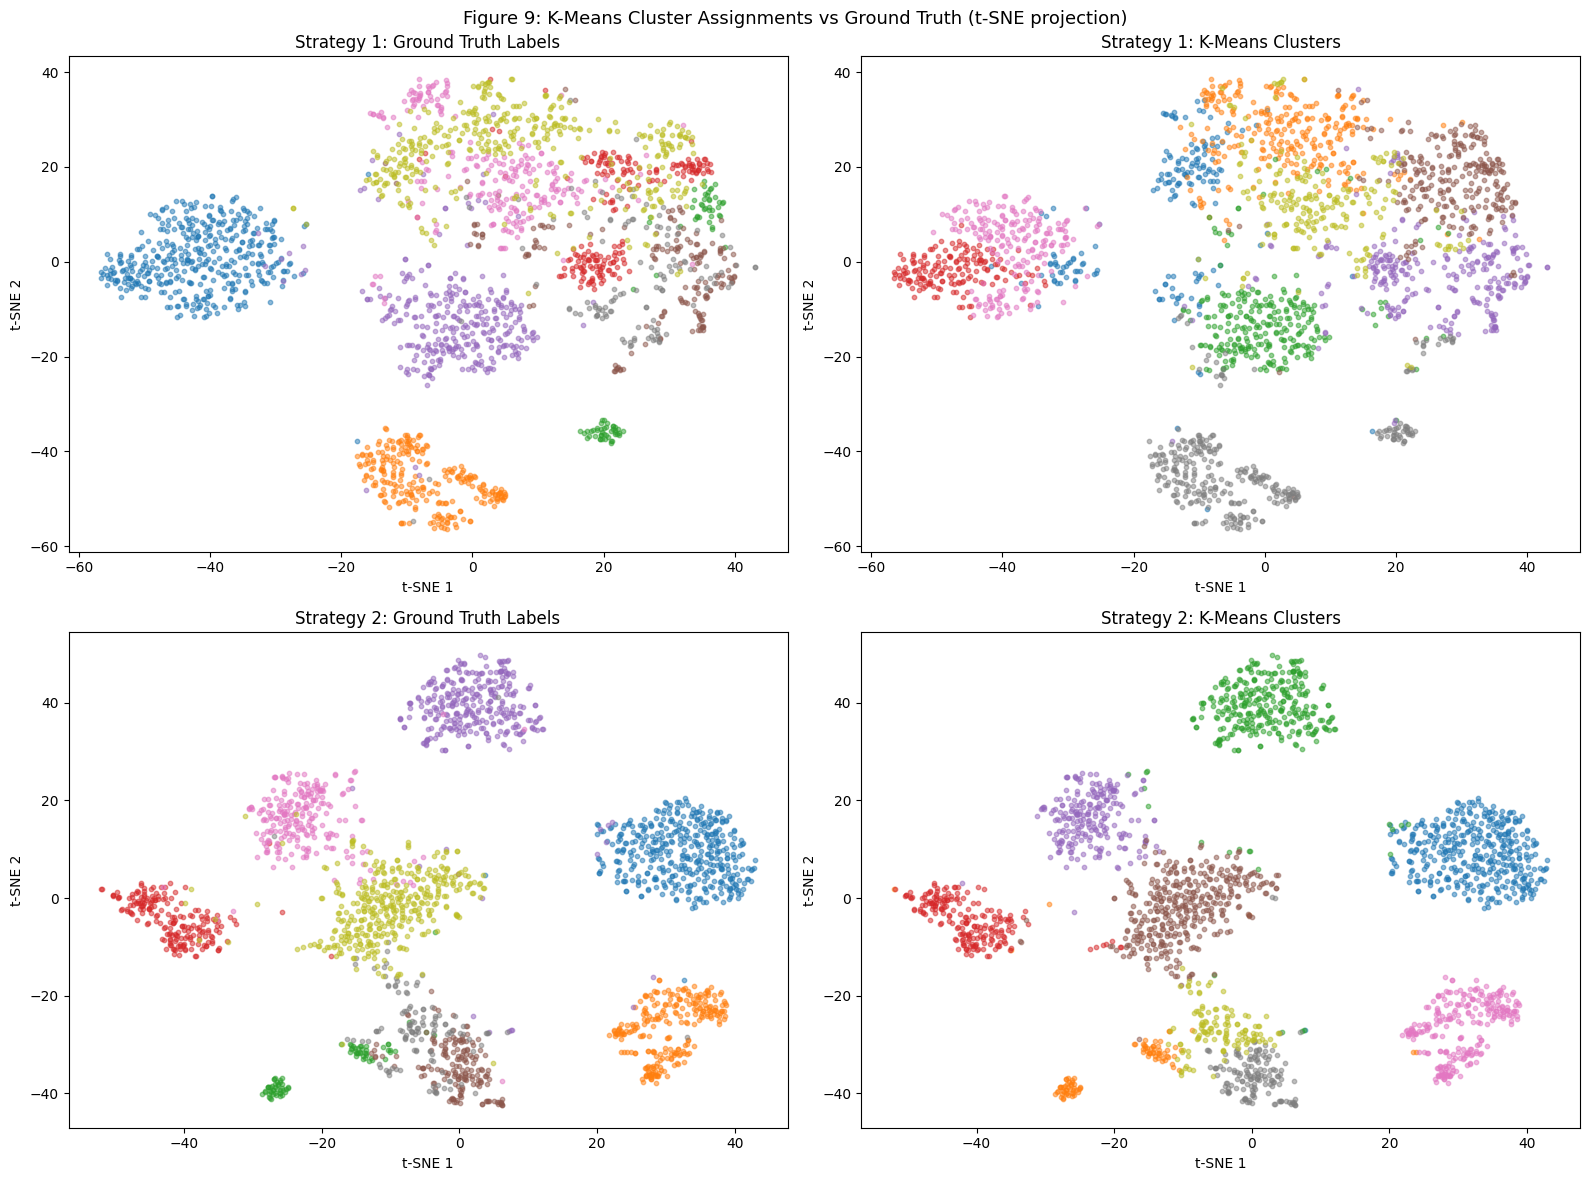

In [28]:
# Figure 9: Visualise k-means cluster assignments on t-SNE plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Strategy 1 - ground truth vs k-means
for class_idx in range(len(labels)):
    mask = labels_s1 == class_idx
    axes[0, 0].scatter(tsne_s1[mask, 0], tsne_s1[mask, 1], label=labels[class_idx], alpha=0.5, s=10)
axes[0, 0].set_title("Strategy 1: Ground Truth Labels")
axes[0, 0].set_xlabel("t-SNE 1")
axes[0, 0].set_ylabel("t-SNE 2")

for c in range(9):
    mask = cluster_labels_s1 == c
    axes[0, 1].scatter(tsne_s1[mask, 0], tsne_s1[mask, 1], label=f"Cluster {c}", alpha=0.5, s=10)
axes[0, 1].set_title("Strategy 1: K-Means Clusters")
axes[0, 1].set_xlabel("t-SNE 1")
axes[0, 1].set_ylabel("t-SNE 2")

# Strategy 2 - ground truth vs k-means
for class_idx in range(len(labels)):
    mask = labels_s2 == class_idx
    axes[1, 0].scatter(tsne_s2[mask, 0], tsne_s2[mask, 1], label=labels[class_idx], alpha=0.5, s=10)
axes[1, 0].set_title("Strategy 2: Ground Truth Labels")
axes[1, 0].set_xlabel("t-SNE 1")
axes[1, 0].set_ylabel("t-SNE 2")

for c in range(9):
    mask = cluster_labels_s2 == c
    axes[1, 1].scatter(tsne_s2[mask, 0], tsne_s2[mask, 1], label=f"Cluster {c}", alpha=0.5, s=10)
axes[1, 1].set_title("Strategy 2: K-Means Clusters")
axes[1, 1].set_xlabel("t-SNE 1")
axes[1, 1].set_ylabel("t-SNE 2")

plt.suptitle("Figure 9: K-Means Cluster Assignments vs Ground Truth (t-SNE projection)", fontsize=13)
plt.tight_layout()
plt.show()

As shown in Table 3, Strategy 2 achieves higher ARI and NMI scores, confirming that its embeddings form clusters better aligned with ground truth tissue types. This is consistent with the t-SNE visualisations (Figures 8–9), where Strategy 2 shows more compact clusters. The head-only model retains generic ImageNet features that do not naturally group histological tissue types, whereas the adapted encoder layers reorganise the embedding space for the classification task.

## Discussion

This assignment compared two transfer learning strategies for fine-tuning DeiT-tiny on the pathMNIST histological classification task. Strategy 1 (head-only) provides a computationally cheap baseline using frozen ImageNet features. Strategy 2 (unfreezing the last two encoder layers) allows adaptation of higher-level representations to the medical imaging domain.

Deeper fine-tuning improved performance across all metrics (Table 2), and produced more discriminative embeddings as confirmed by PCA/t-SNE visualisations (Figures 7–8) and higher clustering scores (Table 3). The validation set was used to select the best learning rate for each strategy, preventing information leakage and ensuring unbiased test set estimates. Future work could explore unfreezing additional layers or applying domain-specific data augmentation.